## Лабораторна робота №9 ##

**Тема:** Класифікація зображень за допомогою згорткової нейронної мережі (CNN)

**Мета роботи:** ознайомитися з принципами роботи згорткових нейронних мереж, навчитися виконувати підготовку зображень, будувати та навчати CNN для задачі класифікації, оцінювати якість моделі за допомогою відповідних метрик і візуалізувати результати її роботи.

In [2]:
from pathlib import Path

FOOD_ROOT = Path("E:/Datasets/food-101")

print("Шлях:", FOOD_ROOT.resolve())
print("Папка існує:", FOOD_ROOT.exists())

print("Класи:", (FOOD_ROOT / "meta/classes.txt").is_file())
print("Train:", (FOOD_ROOT / "meta/train.txt").is_file())
print("Test:", (FOOD_ROOT / "meta/test.txt").is_file())

Шлях: E:\Datasets\food-101
Папка існує: True
Класи: True
Train: True
Test: True


## Визначення трьох класів ##

In [3]:
n = 20

all_classes = sorted(
    (FOOD_ROOT / "meta/classes.txt").read_text(encoding="utf-8").splitlines()
)

assert len(all_classes) == 101
assert 1 <= n <= 41

indices = [n - 1, n + 29, n + 59]
CLASS_NAMES = [all_classes[i] for i in indices]

print("Обрані індекси та класи:")
print(list(zip(indices, CLASS_NAMES)))

print("\nМітки моделі:")
print(dict(enumerate(CLASS_NAMES)))

Обрані індекси та класи:
[(19, 'chicken_quesadilla'), (49, 'grilled_cheese_sandwich'), (79, 'prime_rib')]

Мітки моделі:
{0: 'chicken_quesadilla', 1: 'grilled_cheese_sandwich', 2: 'prime_rib'}


## Перевірка кількості зображень ##

In [4]:
# Читаємо списки зображень
train_ids = (FOOD_ROOT / "meta/train.txt").read_text(
    encoding="utf-8"
).splitlines()

test_ids = (FOOD_ROOT / "meta/test.txt").read_text(
    encoding="utf-8"
).splitlines()

# Перевіряємо кількість зображень кожного класу
for class_name in CLASS_NAMES:
    train_count = sum(
        path.startswith(class_name + "/")
        for path in train_ids
    )

    test_count = sum(
        path.startswith(class_name + "/")
        for path in test_ids
    )

    print(
        f"{class_name}: "
        f"Train = {train_count}, "
        f"Test = {test_count}"
    )

chicken_quesadilla: Train = 750, Test = 250
grilled_cheese_sandwich: Train = 750, Test = 250
prime_rib: Train = 750, Test = 250


## Створення поділу Train / Validation / Test ##

In [5]:
import random

SEED = 42
random.seed(SEED)

# Створюємо списки для трьох частин
split_ids = {
    "train": [],
    "val": [],
    "test": []
}

for class_name in CLASS_NAMES:
    # Відбираємо зображення поточного класу
    class_train = [
        path for path in train_ids
        if path.startswith(class_name + "/")
    ]

    class_test = [
        path for path in test_ids
        if path.startswith(class_name + "/")
    ]

    # Перемішуємо навчальні зображення
    random.shuffle(class_train)

    # Розподіляємо 600 на Train і 150 на Validation
    split_ids["train"].extend(class_train[:600])
    split_ids["val"].extend(class_train[600:])

    # Офіційні тестові зображення залишаємо окремо
    split_ids["test"].extend(class_test)

# Перевіряємо кількість зображень
for split, files in split_ids.items():
    print(f"{split}: {len(files)}")

train: 1800
val: 450
test: 750


## Створення структури папок ##

In [6]:
import shutil

# Папка для підготовленого набору даних
DATA_ROOT = Path("E:/Datasets/food101_lab9")

# Створюємо папки для кожної частини та класу
for split in split_ids:
    for class_name in CLASS_NAMES:
        folder = DATA_ROOT / split / class_name
        folder.mkdir(parents=True, exist_ok=True)

print("Структуру папок створено!")

Структуру папок створено!


## Копіювання зображень ##

In [7]:
for split, files in split_ids.items():
    for file_id in files:
        source = FOOD_ROOT / "images" / f"{file_id}.jpg"
        destination = DATA_ROOT / split / f"{file_id}.jpg"

        shutil.copy2(source, destination)

print("Копіювання зображень завершено!")

Копіювання зображень завершено!


## Перевіримо кількість скопійованих зображень ##

In [8]:
for split in split_ids:
    total = sum(
        len(list((DATA_ROOT / split / class_name).glob("*.jpg")))
        for class_name in CLASS_NAMES
    )

    print(f"{split}: {total}")

train: 1800
val: 450
test: 750


## Перевірте відсутність перетинів і точних дублікатів між частинами за SHA-256 ##

In [9]:
import hashlib

def get_hash(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


hashes = {}

for split in split_ids:
    for class_name in CLASS_NAMES:
        folder = DATA_ROOT / split / class_name

        for file_path in folder.glob("*.jpg"):
            file_hash = get_hash(file_path)

            hashes.setdefault(file_hash, []).append(
                (split, file_path)
            )

duplicates = {
    h: files for h, files in hashes.items()
    if len(files) > 1
}

print("Усього зображень:", len(hashes))
print("Кількість груп дублікатів:", len(duplicates))

Усього зображень: 3000
Кількість груп дублікатів: 0


In [11]:
split_paths = {}

for split in split_ids:
    paths = set()

    for class_name in CLASS_NAMES:
        folder = DATA_ROOT / split / class_name

        for file_path in folder.glob("*.jpg"):
            paths.add(f"{class_name}/{file_path.name}")

    split_paths[split] = paths


split_names = list(split_paths.keys())

for i, split1 in enumerate(split_names):
    for split2 in split_names[i + 1:]:
        common = split_paths[split1] & split_paths[split2]

        print(f"{split1} - {split2}: {len(common)} перетинів")

train - val: 0 перетинів
train - test: 0 перетинів
val - test: 0 перетинів


## Створення manifest.json ##

In [12]:
import json

manifest = {
    "seed": 42,
    "classes": CLASS_NAMES,
    "splits": {}
}

for split in split_ids:
    manifest["splits"][split] = []

    for class_name in CLASS_NAMES:
        folder = DATA_ROOT / split / class_name

        for file_path in sorted(folder.glob("*.jpg")):
            relative_path = file_path.relative_to(DATA_ROOT).as_posix()
            manifest["splits"][split].append(relative_path)

with open(DATA_ROOT / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, ensure_ascii=False, indent=4)

print("manifest.json успішно створено!")

manifest.json успішно створено!


## Перевірка зображень ##

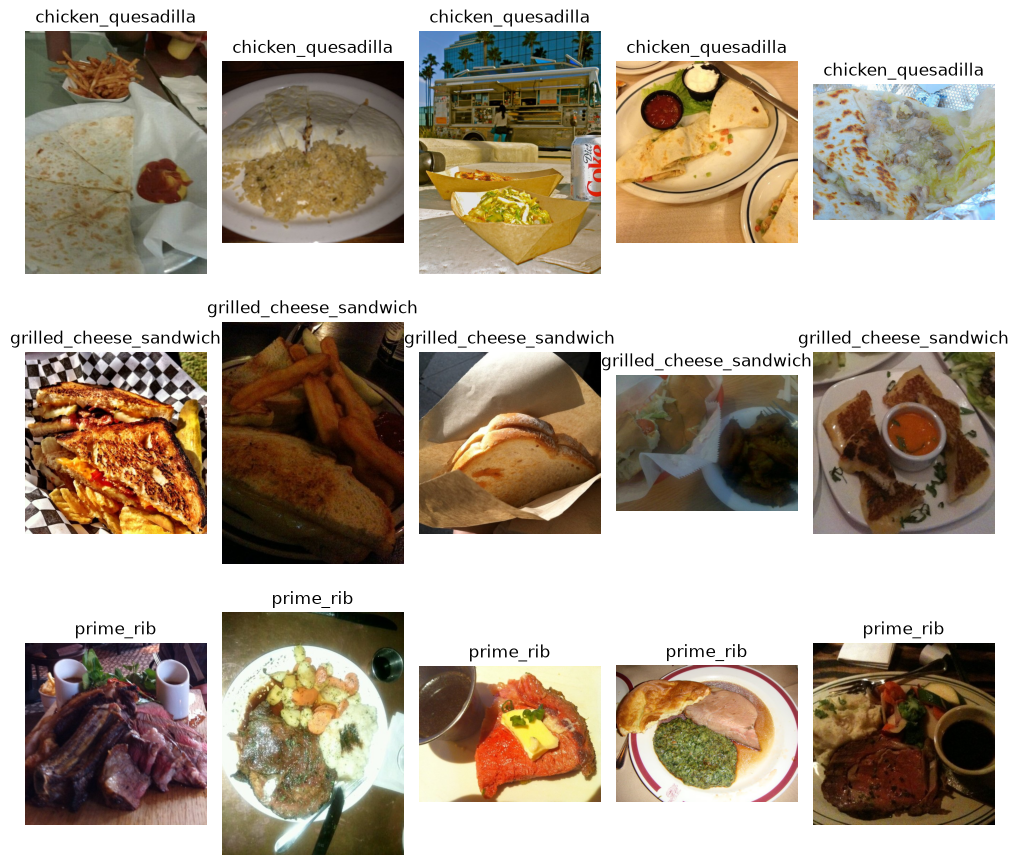

In [20]:
import matplotlib.pyplot as plt
from tensorflow import keras
plt.figure(figsize=(10, 9))

for class_index, class_name in enumerate(CLASS_NAMES):
    folder = DATA_ROOT / "train" / class_name
    images = list(folder.glob("*.jpg"))[:5]

    for image_index, image_path in enumerate(images):
        plt.subplot(3, 5, class_index * 5 + image_index + 1)

        img = keras.utils.load_img(image_path)

        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
from PIL import Image

bad_images = []

for split in split_ids:
    for class_name in CLASS_NAMES:
        folder = DATA_ROOT / split / class_name

        for file_path in folder.glob("*.jpg"):
            try:
                with Image.open(file_path) as img:
                    img.verify()
            except Exception:
                bad_images.append(file_path)

print("Пошкоджених зображень:", len(bad_images))

Пошкоджених зображень: 0


## Завантаження батчів ##

In [22]:
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

IMAGE_SIZE = (128, 128)

def load_split(part, training=False):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / part,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=32,
        shuffle=training,
        seed=42
    )

train_ds = load_split("train", True).prefetch(tf.data.AUTOTUNE)

val_ds = load_split("val").prefetch(tf.data.AUTOTUNE)

test_ds = load_split("test").prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))

print(images.shape, labels.shape)

print(float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
(32, 128, 128, 3) (32,)
0.0 255.0


## Перевіряємо розрахунок кодом ##

In [23]:
X = np.array([
    [1, 2, 0],
    [0, 1, 3],
    [2, 2, 1]
], dtype=np.float32)

K = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

result = np.zeros((2, 2))

for i in range(2):
    for j in range(2):
        window = X[i:i+2, j:j+2]
        result[i, j] = np.sum(window * K)

print("Результат згортки:")
print(result)

result_bias = result + 1
result_relu = np.maximum(0, result_bias)

print("Після додавання bias і ReLU:")
print(result_relu)

Результат згортки:
[[ 0. -1.]
 [-2.  0.]]
Після додавання bias і ReLU:
[[1. 0.]
 [0. 1.]]


## Створюємо та переглядаємо модель ##

In [24]:
def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128, 128, 3))

    x = layers.Rescaling(1.0 / 255)(inputs)

    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(
            filters, 3,
            padding="same",
            activation="relu",
            name=f"conv{i}"
        )(x)

        x = layers.MaxPooling2D(2)(x)

    x = layers.GlobalAveragePooling2D()(x)

    if dropout > 0:
        x = layers.Dropout(dropout)(x)

    outputs = layers.Dense(3, activation="softmax")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy")
        ]
    )

    return model
model = make_model()
model.summary()

assert model.count_params() == 23779

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

## Створення функції навчання та запуск ##

In [26]:
def fit_model(model):
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=30,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ]
    )
history = fit_model(model)
base_val = model.evaluate(val_ds, verbose=0, return_dict=True)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.6272 - loss: 0.8297 - val_accuracy: 0.6067 - val_loss: 0.8410
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.6256 - loss: 0.8380 - val_accuracy: 0.6022 - val_loss: 0.8921
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.6294 - loss: 0.8199 - val_accuracy: 0.6267 - val_loss: 0.8264
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.6278 - loss: 0.8153 - val_accuracy: 0.6289 - val_loss: 0.8328
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.6478 - loss: 0.7929 - val_accuracy: 0.6222 - val_loss: 0.8311
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.6217 - loss: 0.8271 - val_accuracy: 0.6178 - val_loss: 0.8292
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.6361 - loss: 0.8182 - val_accuracy: 0.6133 - val_loss: 0.8667
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.6411 - loss: 0.8006 - val_accuracy: 0.6222 - 

## Графіки навчання мережі ##

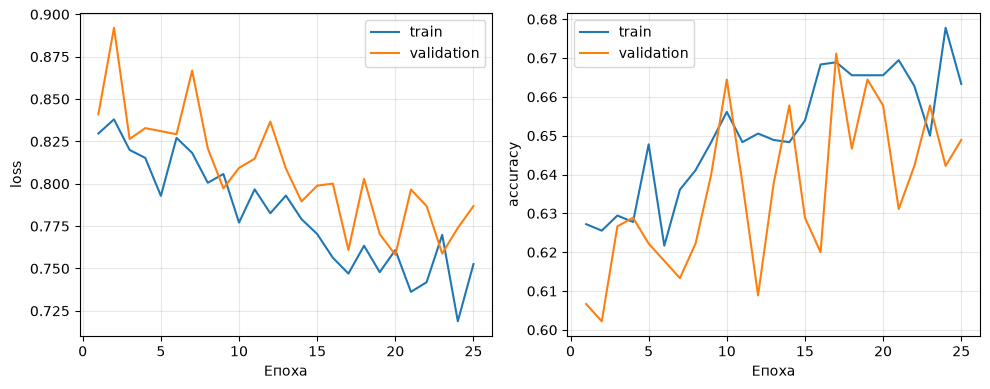

In [27]:
def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    epochs = range(1, len(history.history["loss"]) + 1)

    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history.history[metric], label="train")
        ax.plot(epochs, history.history["val_" + metric], label="validation")

        ax.set(xlabel="Епоха", ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(history)

In [28]:
best_epoch = np.argmin(history.history["val_loss"]) + 1
epochs_trained = len(history.history["loss"])

print("Фактична кількість епох:", epochs_trained)
print("Найкраща епоха за val_loss:", best_epoch)
print("Найкращий val_loss:", min(history.history["val_loss"]))

Фактична кількість епох: 25
Найкраща епоха за val_loss: 20
Найкращий val_loss: 0.7580650448799133


## Гіпотеза ##
Dropout допоможе зменшити перенавчання та, можливо, покращить результати на валідаційних даних.

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.3467 - loss: 1.0955 - val_accuracy: 0.4444 - val_loss: 1.0697
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.4294 - loss: 1.0605 - val_accuracy: 0.4822 - val_loss: 1.0217
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.4583 - loss: 1.0222 - val_accuracy: 0.5622 - val_loss: 0.9637
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.4872 - loss: 0.9941 - val_accuracy: 0.5311 - val_loss: 0.9506
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.5217 - loss: 0.9570 - val_accuracy: 0.5667 - val_loss: 0.9343
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.5200 - loss: 0.9613 - val_accuracy: 0.5511 - val_loss: 0.9094
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - accuracy: 0.5467 - loss: 0.9409 - val_accuracy: 0.5644 - val_loss: 0.9185
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - accuracy: 0.5483 - loss: 0.9287 - val_accuracy: 0.5867 - v

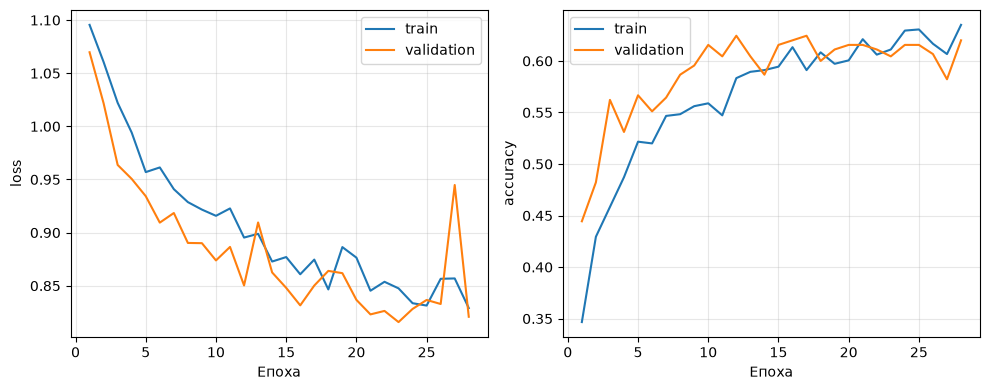

In [29]:
keras.utils.set_random_seed(42)

changed_model = make_model(dropout=0.3)

changed_history = fit_model(changed_model)

changed_val = changed_model.evaluate(
    val_ds, verbose=0, return_dict=True
)

plot_history(changed_history)

selected_model = (
    changed_model
    if changed_val["loss"] < base_val["loss"]
    else model
)

In [30]:
print("Базова модель:", base_val)
print("Модель з Dropout:", changed_val)

print("Параметри базової:", model.count_params())
print("Параметри Dropout:", changed_model.count_params())

Базова модель: {'accuracy': 0.6577777862548828, 'loss': 0.7580650448799133}
Модель з Dropout: {'accuracy': 0.6044444441795349, 'loss': 0.8158184289932251}
Параметри базової: 23779
Параметри Dropout: 23779


## Фінальне оцінювання та інтерпретація CNN ##

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

print(selected_model.evaluate(
    test_ds,
    verbose=0,
    return_dict=True
))
# Отримуємо фактичні мітки класів
y_true = np.concatenate([y.numpy() for _, y in test_ds])

# Отримуємо ймовірності передбачення моделі
probabilities = selected_model.predict(test_ds, verbose=0)

# Визначаємо клас із найбільшою ймовірністю
y_pred = probabilities.argmax(axis=1)

print("Форма справжніх міток:", y_true.shape)
print("Форма прогнозів:", y_pred.shape)
print("Форма ймовірностей:", probabilities.shape)

# Формуємо звіт класифікації
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))


{'accuracy': 0.6973333358764648, 'loss': 0.7228865623474121}
                         precision    recall  f1-score   support

     chicken_quesadilla       0.67      0.66      0.66       250
grilled_cheese_sandwich       0.60      0.64      0.62       250
              prime_rib       0.83      0.80      0.82       250

               accuracy                           0.70       750
              macro avg       0.70      0.70      0.70       750
           weighted avg       0.70      0.70      0.70       750



## Матриця помилок ##

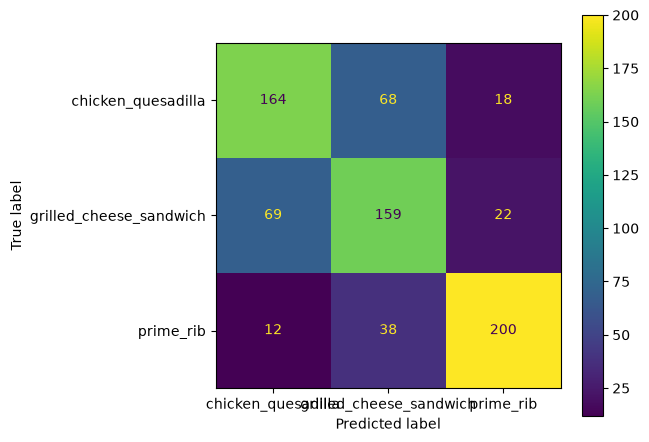

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    display_labels=CLASS_NAMES
)

plt.tight_layout()
plt.show()

## Візуалізація 6 прогнозів ##

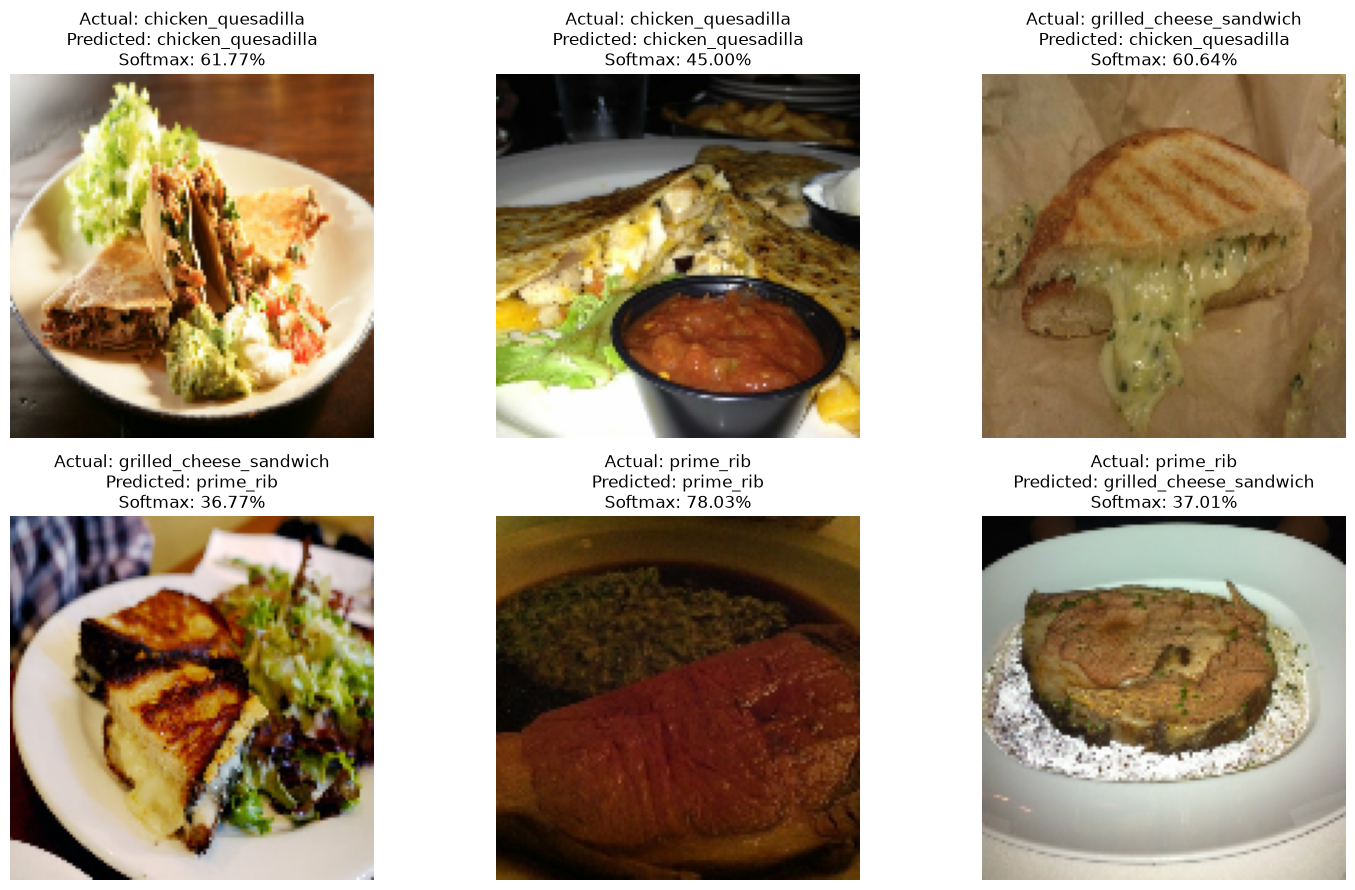

In [ ]:
# Збираємо по 2 зображення кожного класу
images_to_show = []
labels_to_show = []
class_counts = {0: 0, 1: 0, 2: 0}

for images, labels in test_ds:
    for i in range(len(labels)):
        label = int(labels[i].numpy())

        if class_counts[label] < 2:
            images_to_show.append(images[i].numpy())
            labels_to_show.append(label)
            class_counts[label] += 1

    if all(count == 2 for count in class_counts.values()):
        break

# Отримуємо прогнози моделі
images_array = np.array(images_to_show)
probabilities = selected_model.predict(images_array, verbose=0)

y_pred_show = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)

# Відображаємо результати
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    ax.imshow(images_array[i].astype("uint8"))

    actual = CLASS_NAMES[labels_to_show[i]]
    predicted = CLASS_NAMES[y_pred_show[i]]

    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Softmax: {confidence[i]:.2%}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

## Показуємо помилки моделі ##

Кількість помилкових прогнозів: 227


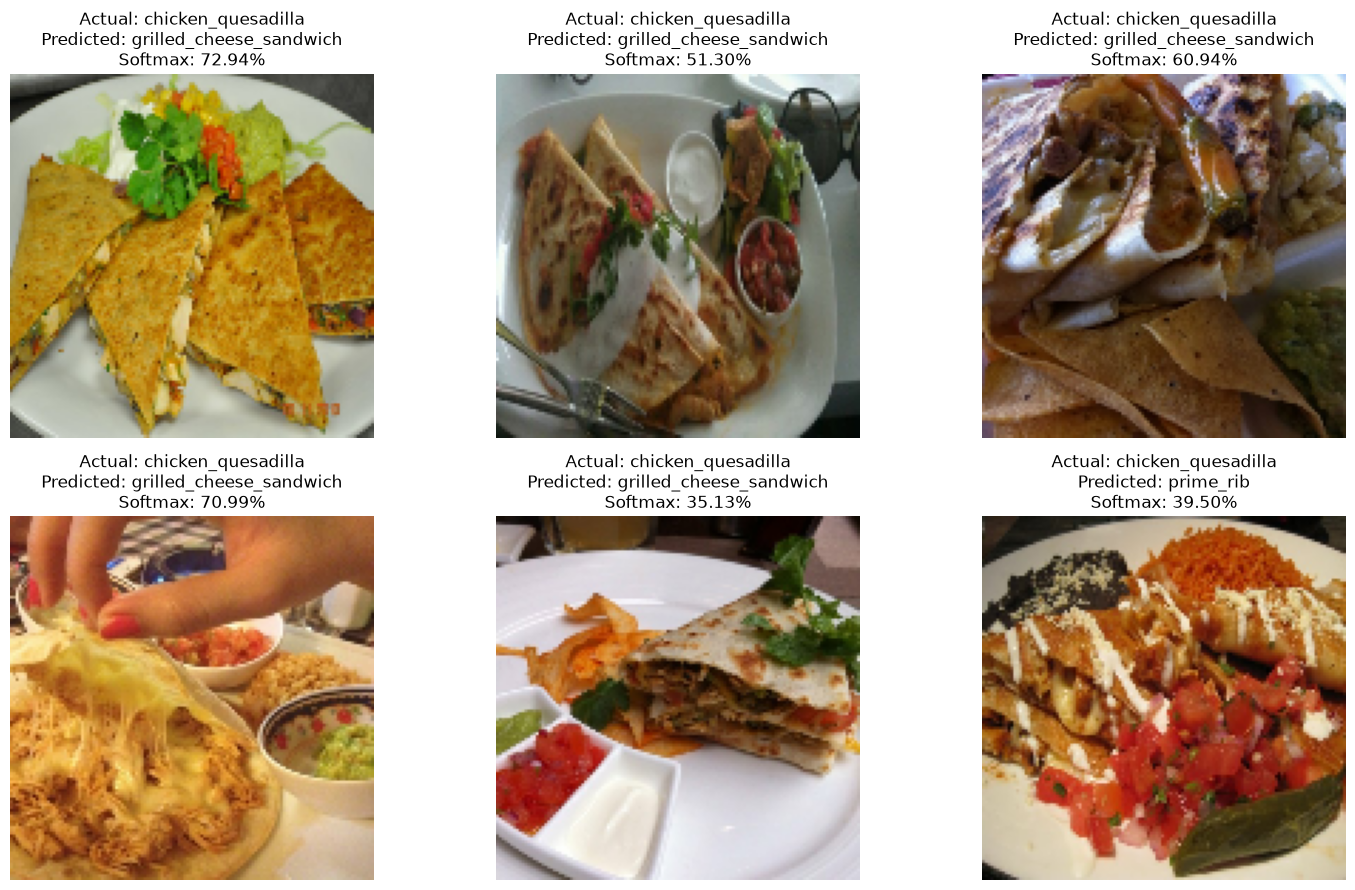

In [37]:
# Знаходимо індекси неправильних прогнозів
wrong_indices = np.where(y_true != y_pred)[0]

# Кількість усіх помилок
print("Кількість помилкових прогнозів:", len(wrong_indices))

# Показуємо максимум 6 помилок
wrong_indices = wrong_indices[:6]

# Отримуємо всі тестові зображення
test_images = np.concatenate([
    x.numpy() for x, _ in test_ds
])

# Отримуємо ймовірності для всіх тестових зображень
test_probabilities = selected_model.predict(
    test_images, verbose=0
)

# Відображаємо помилкові прогнози
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    if i < len(wrong_indices):
        idx = wrong_indices[i]

        ax.imshow(test_images[idx].astype("uint8"))

        actual = CLASS_NAMES[y_true[idx]]
        predicted = CLASS_NAMES[y_pred[idx]]
        score = test_probabilities[idx].max()

        ax.set_title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Softmax: {score:.2%}"
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

## Візуалізація карт активацій ##

In [38]:
# Створюємо модель, яка повертає результат першого Conv
feature_model = keras.Model(
    selected_model.inputs,
    selected_model.get_layer("conv1").output
)

# Беремо одне зображення з тестової вибірки
example, _ = next(iter(test_ds))

# Отримуємо карти активацій
feature_maps = feature_model(
    example[:1],
    training=False
)

print("Розмір карт активацій:", feature_maps.shape)

Розмір карт активацій: (1, 128, 128, 16)


## Відображаємо Feature Maps ##

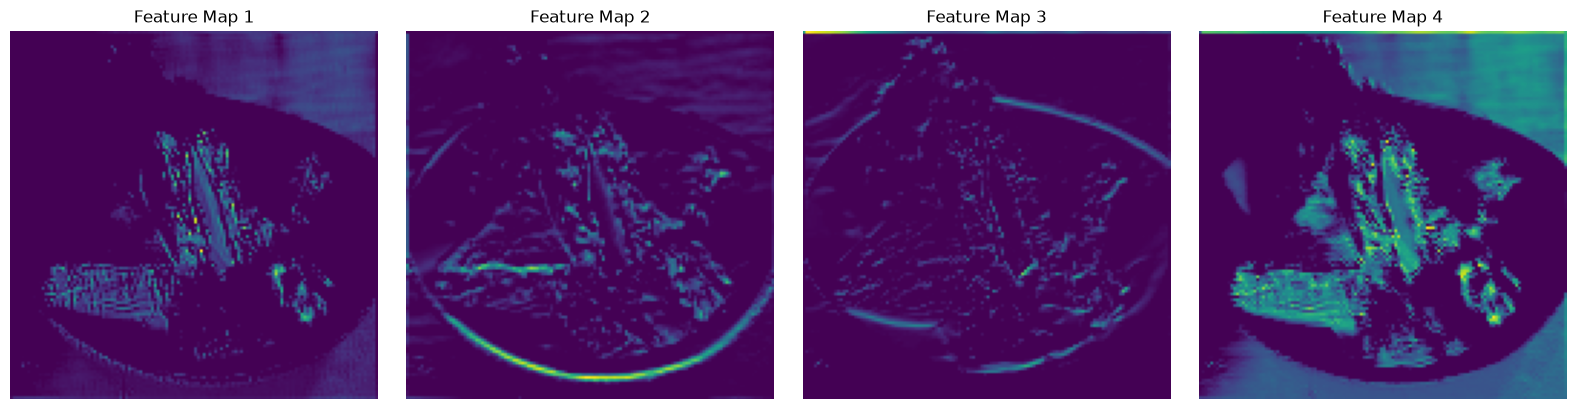

In [39]:
# Відображаємо перші 4 карти активацій
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, ax in enumerate(axes):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Feature Map {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Прогноз на власному фото ##

In [40]:
# Шлях до власного зображення
image_path = "my_food.jpg"

# Завантажуємо та змінюємо розмір зображення
img = keras.utils.load_img(
    image_path,
    target_size=(128, 128),
    interpolation="bilinear"
)

# Перетворюємо зображення на масив
img_array = keras.utils.img_to_array(img)

# Додаємо batch-вимір
img_array = np.expand_dims(img_array, axis=0)

# Отримуємо прогноз моделі
prediction = selected_model.predict(img_array, verbose=0)

# Визначаємо передбачений клас
predicted_class = prediction.argmax(axis=1)[0]

# Виводимо результат
print("Передбачений клас:", CLASS_NAMES[predicted_class])
print("Оцінка Softmax:", prediction.max())

Передбачений клас: grilled_cheese_sandwich
Оцінка Softmax: 0.8752461


## Зберігаємо модель ##

In [41]:
# Зберігаємо навчену модель
selected_model.save("food_cnn.keras")

# Зберігаємо назви класів
Path("class_names.json").write_text(
    json.dumps(CLASS_NAMES, ensure_ascii=False),
    encoding="utf-8"
)

print("Модель і назви класів успішно збережено!")

Модель і назви класів успішно збережено!


In [43]:
manifest = {
    "dataset": "Food-101",
    "classes": CLASS_NAMES,
    "seed": 42,
    "image_size": [128, 128],
    "split": {
        "train": 1800,
        "validation": 450,
        "test": 750
    }
}

Path("manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=4),
    encoding="utf-8"
)

print("manifest.json успішно створено!")

manifest.json успішно створено!


## Створюємо README.md ##

In [44]:
readme = """# Lab9 — Convolutional Neural Network (CNN)

## Мета роботи
Побудова та навчання згорткової нейронної мережі (CNN)
для класифікації зображень страв із набору Food-101.

## Набір даних
Food-101:
https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/

Використано три класи:
- chicken_quesadilla
- grilled_cheese_sandwich
- prime_rib

## Параметри експерименту
- Seed: 42
- Розмір зображень: 128x128
- Train: 1800 зображень
- Validation: 450 зображень
- Test: 750 зображень

## Результати
- Test accuracy: 69.73%
- Test loss: 0.7229
- Macro-F1: 0.70

## Структура проєкту
- lab9_cnn.ipynb — код, пояснення та результати
- manifest.json — інформація про дані та поділ вибірок
- class_names.json — порядок класів
- results/ — результати експериментів та графіки
- .gitignore — виключення файлів даних та кешу

## Запуск
1. Завантажити набір Food-101.
2. Налаштувати шлях до даних у ноутбуці.
3. Встановити необхідні бібліотеки.
4. Відкрити lab9_cnn.ipynb.
5. Виконати всі клітинки зверху вниз.

## Примітка
Набір Food-101 та навчена модель не включаються
до GitHub-репозиторію.
"""

Path("README.md").write_text(
    readme,
    encoding="utf-8"
)

print("README.md успішно створено!")

README.md успішно створено!
